# 13: Can a depth-profile artifact fake keV screening, and what shape do the beam data allow?

Karahadian et al. (Nat. Commun. 2026, arXiv:2512.06212) report $U_e$ = 0.8 ± 0.2 keV (beam-loaded Pd), 1.7 ± 0.2 keV (electrochemically loaded PdD) and 0.9 ± 0.2 keV (TiD). Their method, as given in the full text:
* **thick-target** d(d,p)t yields at $E_{cm}$ = 0.25–6.5 keV;
* yields **normalised to the 6.5 keV point**;
* a constant-$U_e$ screened cross-section **fitted from 6.5 down to 2.5 keV** (Ti: above 2.0 keV);
* the authors note that $U_e$ may depend on depth, because deuterium loading and defects vary near the surface.

This notebook asks three questions.

1. **Artifact:** with *no* screening, how large a $U_e$ can a near-surface deuterium excess fake under exactly that fitting procedure? (Notebook 02 used a phenomenological $g(E)$; here the depth profile enters a thick-target integral.)
2. **Shape fitted to data:** our bounds fix the screening strength by matching $U_e$ at the turning point 0.004 Å (`beam_matched_dU`). Here we instead require the profile's **WKB** enhancement to reproduce the fitted $U_e$ through the same thick-target, 6.5 keV-normalised fit. How different is the strength, and which short ranges distort the yield curve more than the ±0.2 keV uncertainty allows?
3. **Does Claim A move** if the data-fitted strength replaces the beam-matched one?

**Model.** $Y(E_0) \propto \int_0^{E_0} n(\xi)\,\sigma(E)\,f(E)/S(E)\,dE$, with stopping $S \propto E^p$. Electronic stopping of slow hydrogen gives $p = 0.5$; $p$ = 0.3–0.7 is scanned because nuclear stopping matters at keV. Depth is $\xi = (E_0^{1-p} - E^{1-p})/6.5^{1-p}$, in units of the range at 6.5 keV, so no absolute stopping power is needed. Here $\sigma \propto e^{-B_G/\sqrt{E}}/E$ (constant S-factor over 0.05–6.5 keV).

In [1]:
import numpy as np, matplotlib.pyplot as plt, warnings
from scipy import optimize
from cfsolve import *
warnings.filterwarnings("ignore", category=RuntimeWarning)
plt.rcParams.update({"axes.spines.top":False,"axes.spines.right":False,"axes.grid":True,"grid.alpha":.25,"font.size":10})
BLUE, ORANGE, AQUA, MAGENTA, INK = "#2a78d6","#eb6834","#1baf7a","#e87ba4","#0b0b0b"
E2, MU, HC, RN, B_G = 1440.0, 937.8e3, 197327.0, 5.0, 31.3970     # keV fm, keV, keV fm, fm, sqrt(keV)
EFIT = np.linspace(2.5, 6.5, 9)
def f_shift(E, U): return np.exp(B_G/np.sqrt(E) - B_G/np.sqrt(E + U))
def sig(E, U=0.0): return np.exp(-B_G/np.sqrt(E))/E*f_shift(E, U)
def thick(E0, fenh=lambda E: 1.0, dens=lambda xi: 1.0, p=0.5):
    E = E0 - np.geomspace(1e-7*E0, E0 - 0.05, 6000)[::-1]
    xi = (E0**(1-p) - E**(1-p))/6.5**(1-p)
    return np.trapezoid(dens(xi)*np.exp(-B_G/np.sqrt(E))/E*fenh(E)/E**p, E)
def rel(fenh=lambda E: 1.0, dens=lambda xi: 1.0, p=0.5):
    y = np.array([thick(e, fenh, dens, p) for e in EFIT]); return y/y[-1]
def fitU(yrel, p=0.5):
    # what the experiment reports: constant-U thick-target curve, uniform density, normalised at 6.5 keV
    return optimize.minimize_scalar(lambda U: np.sum((np.log(rel(lambda E: f_shift(E, U), p=p)) - np.log(yrel))**2),
                                    bounds=(-1, 12), method="bounded").x
def gamow(E, dV=None):
    V = lambda R: E2/R + (dV(R) if dV else 0.0)
    Rtp = optimize.brentq(lambda R: V(R) - E, RN, 1e8)
    R = np.geomspace(RN, Rtp, 4000)
    return 2*np.trapezoid(np.sqrt(2*MU*np.clip(V(R) - E, 0, None)), R)/HC
print(f"check 1: constant U = 1.7 keV recovered by the fit: {fitU(rel(lambda E: f_shift(E, 1.7))):.4f} keV")
g_far = lambda R: -1.7*np.ones_like(np.asarray(R, float))
print(f"check 2: WKB enhancement for a uniform 1.7 keV shift at 2.5 keV: {np.exp(gamow(2.5) - gamow(2.5, g_far)):.2f} "
      f"vs energy-shift formula {f_shift(2.5, 1.7):.2f}")

check 1: constant U = 1.7 keV recovered by the fit: 1.7000 keV
check 2: WKB enhancement for a uniform 1.7 keV shift at 2.5 keV: 93.20 vs energy-shift formula 93.41


## 1. How much screening can a depth profile fake?

Two families of near-surface excess are scanned: a layer, $n = 1 + A$ for $\xi < t$, and an exponential, $n = 1 + A e^{-\xi/t}$.

**The limit.** Yield is linear in $n$, and per unit depth the low-energy beam always loses relatively more energy than the 6.5 keV beam. A non-negative profile therefore raises the low-energy points most when all of the yield comes from the surface itself. That is the *thin-target limit*, $Y \propto \sigma(E_0)$, and it does not depend on $n(\xi)$.

In [2]:
print(" profile       t (R_6.5)   A=0.5   A=2    A=10   A=1e4   (fake U_e in eV, true U_e = 0, p = 0.5)")
for kind, dens in [("layer", lambda A, t: (lambda xi: 1 + A*(xi < t))), ("exponential", lambda A, t: (lambda xi: 1 + A*np.exp(-xi/t)))]:
    for t in [0.002, 0.01, 0.05, 0.2]:
        print(f" {kind:12s} {t:8.3f}  " + "".join(f"{fitU(rel(dens=dens(A, t)))*1e3:7.0f}" for A in [0.5, 2, 10, 1e4]))
thin = sig(EFIT)/sig(6.5)
print("\nthin-target limit (supremum over all non-negative depth profiles):")
U_thin = {}
for p in [0.3, 0.5, 0.7]:
    U_thin[p] = fitU(thin, p=p); print(f"   stopping S ~ E^{p}: fake U_e <= {U_thin[p]*1e3:.0f} eV")

 profile       t (R_6.5)   A=0.5   A=2    A=10   A=1e4   (fake U_e in eV, true U_e = 0, p = 0.5)
 layer           0.002        6     22     86    349


 layer           0.010       23     76    194    323
 layer           0.050       46    109    175    207


 layer           0.200        7     13     18     20
 exponential     0.002        6     21     83    343


 exponential     0.010       20     66    173    297
 exponential     0.050       32     82    141    172


 exponential     0.200       18     39     57     64

thin-target limit (supremum over all non-negative depth profiles):
   stopping S ~ E^0.3: fake U_e <= 435 eV
   stopping S ~ E^0.5: fake U_e <= 357 eV
   stopping S ~ E^0.7: fake U_e <= 283 eV


In [3]:
# Lower bound on genuine enhancement: if ALL yield came from the surface AND there were true screening U_true,
# what U_true reproduces each reported value?
print("genuine screening still required under the most extreme depth artifact (thin-target limit):")
for lab, Um in [("Pd, beam-loaded", 0.8), ("TiD", 0.9), ("PdD, electrochemical", 1.7)]:
    out = []
    for p in [0.3, 0.5, 0.7]:
        out.append(optimize.brentq(lambda Ut: fitU(sig(EFIT, Ut)/sig(6.5, Ut), p=p) - Um, 0.0, 5.0))
    print(f"   {lab:22s} U_meas = {Um:.1f} keV  ->  U_true >= {min(out):.2f}–{max(out):.2f} keV (p = 0.3–0.7)")

genuine screening still required under the most extreme depth artifact (thin-target limit):


   Pd, beam-loaded        U_meas = 0.8 keV  ->  U_true >= 0.32–0.51 keV (p = 0.3–0.7)


   TiD                    U_meas = 0.9 keV  ->  U_true >= 0.41–0.61 keV (p = 0.3–0.7)


   PdD, electrochemical   U_meas = 1.7 keV  ->  U_true >= 1.15–1.47 keV (p = 0.3–0.7)


## 2. Screening shape fitted to the data

For each profile shape and range $\ell$, the strength $\Delta U$ is solved so that the **WKB** enhancement of $V = e^2/R - \Delta U\,g(R/\ell)$, put through the experiment's thick-target constant-$U$ fit, returns the reported $U_e$. Two quantities are reported: the ratio to our beam-matched strength, and the largest deviation of the profile's relative-yield curve from the best constant-$U$ curve over 2.5–6.5 keV. The distortion threshold is the deviation that a $\pm$0.2 keV change in $U_e$ produces. That is a proxy for the published uncertainty, since the individual data points are not tabulated.

In [4]:
EG = np.geomspace(0.05, 6.5, 70); G0 = np.array([gamow(e) for e in EG])
def fenh_profile(dU, ell_fm, shape):
    g = PROFILES[shape]
    lf = np.array([G0[i] - gamow(e, lambda R: -dU*g(np.asarray(R)/ell_fm)) for i, e in enumerate(EG)])
    return lambda E: np.exp(np.interp(np.log(E), np.log(EG), lf))
def data_fitted_dU(U, ell_A, shape):
    ell = ell_A*1e5; bm = beam_matched_dU(U*1e3, ell_A, shape)/1e3
    try: dU = optimize.brentq(lambda dU: fitU(rel(fenh_profile(dU, ell, shape))) - U, 1e-4, max(3*bm, 2*U), xtol=1e-4)
    except ValueError: return np.nan, np.nan, bm
    dev = np.max(np.abs(rel(fenh_profile(dU, ell, shape))/rel(lambda E: f_shift(E, U)) - 1))
    return dU, dev, bm
def threshold(U):
    return np.max(np.abs(rel(lambda E: f_shift(E, U + 0.2))/rel(lambda E: f_shift(E, U)) - 1))
ELL13 = np.logspace(np.log10(0.002), np.log10(0.4), 40)
FIT = {}
for U in [0.8, 1.7]:
    thr = threshold(U); print(f"\nU_e = {U} keV: distortion threshold (±0.2 keV equivalent) = {100*thr:.1f}%")
    print(f"   {'shape':12s} {'ell_min (A)':>11s}   dU_fit/dU_beam at ell = 0.003, 0.004, 0.01, 0.03 A")
    for sh in PROFILES:
        res = [data_fitted_dU(U, l, sh) for l in ELL13]; FIT[(U, sh)] = res
        dev = np.array([r[1] for r in res]); ok = np.where(dev < thr)[0]
        lmin = ELL13[ok[0]] if len(ok) else np.nan
        rat = [data_fitted_dU(U, l, sh) for l in [0.003, 0.004, 0.01, 0.03]]
        print(f"   {sh:12s} {lmin:11.4f}   " + "  ".join(f"{r[0]/r[2]:.2f}" if np.isfinite(r[0]) else " — " for r in rat))


U_e = 0.8 keV: distortion threshold (±0.2 keV equivalent) = 49.7%
   shape        ell_min (A)   dU_fit/dU_beam at ell = 0.003, 0.004, 0.01, 0.03 A


   exponential       0.0020   1.12  1.09  1.04  1.01


   gaussian          0.0039   1.01  1.12  1.03  1.00


   step              0.0045   0.18  1.19  1.00  1.00


   yukawa            0.0020   1.05  1.04  1.02  1.01

U_e = 1.7 keV: distortion threshold (±0.2 keV equivalent) = 33.0%
   shape        ell_min (A)   dU_fit/dU_beam at ell = 0.003, 0.004, 0.01, 0.03 A


   exponential       0.0026   0.88  0.92  0.98  0.99


   gaussian          0.0045   0.64  0.82  0.99  1.00


   step              0.0045   0.16  0.82  1.02  1.00


   yukawa            0.0020   0.97  0.98  0.99  1.00


## 3. Does Claim A move?

The neutron-limit crossing is recomputed for the 2.75 Å lattice pair (as in notebook 04b), using the data-fitted strength $\Delta U_{fit}(\ell)$ in place of the beam-matched one.

In [5]:
NU0 = 37e-3/4.135667e-15; LL = np.log10(2e-26)
def band(d0A, dUs, shape, ells):
    Vb = V_lattice(d0_A=d0A); d0 = d0A/BOHR_A; Rmax = d0 + 7; Rmin = 0.4*d0
    E_lat = solve(Vb, Rmax, Rmin_well=Rmin)["E"]; out = []
    for dU, l in zip(dUs, ells):
        if not np.isfinite(dU): out.append(np.nan); continue
        ex = extra_screening(dU, l, shape); V = lambda R: Vb(R) + ex(R)
        try: out.append(solve(V, Rmax, Rmin_well=Rmin)["log10_rate"])
        except Collapse:
            B = solve(V, Rmax, Rmin_well=0.0); r = np.logspace(-4, np.log10(Rmax), 200000); v = V(r)
            imin = np.argmin(np.where(r < Rmin, v, np.inf)); sel = (r > r[imin]) & (r < d0) & (v > E_lat)
            G = 2*np.trapezoid(np.sqrt(2*MU_DD*np.clip(v[sel]-E_lat, 0, None)), r[sel])
            out.append(min(np.log10(NU0) - G/np.log(10), B["log10_rate"]))
    return np.array(out)
cross = lambda e: ELL13[np.where(e > LL)[0][0]] if np.any(e > LL) else np.nan
print(f"{'U_e':>5s} {'shape':12s} {'bound, beam-matched':>20s} {'bound, data-fitted':>19s}")
BOUNDS = []
for U in [0.8, 1.7]:
    for sh in PROFILES:
        e_bm = band(2.75, [beam_matched_dU(U*1e3, l, sh) for l in ELL13], sh, ELL13)
        e_fit = band(2.75, [r[0]*1e3 for r in FIT[(U, sh)]], sh, ELL13)
        BOUNDS.append((U, sh, cross(e_bm), cross(e_fit)))
        print(f"{U:5.1f} {sh:12s} {cross(e_bm):20.4f} {cross(e_fit):19.4f}")

  U_e shape         bound, beam-matched  bound, data-fitted


  0.8 exponential                0.1349              0.1349


  0.8 gaussian                   0.3048              0.3048


  0.8 step                          nan                 nan


  0.8 yukawa                     0.0134              0.0134


  1.7 exponential                0.1178              0.1178


  1.7 gaussian                   0.2661              0.2661


  1.7 step                          nan                 nan


  1.7 yukawa                     0.0045              0.0045


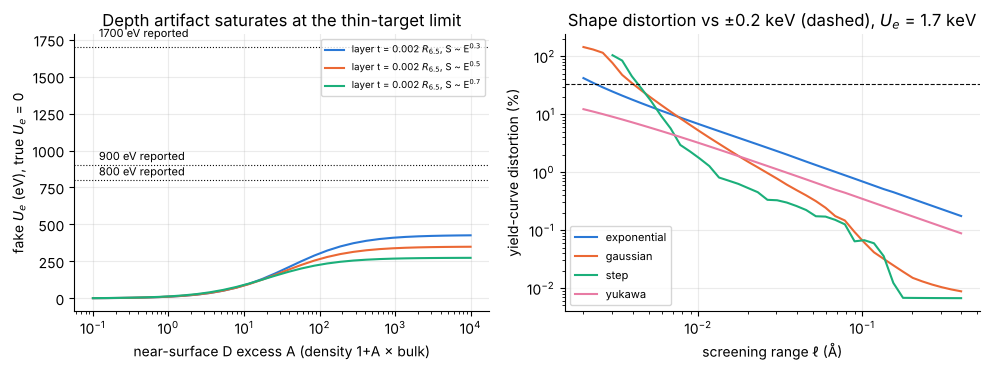

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for p, c in zip([0.3, 0.5, 0.7], [BLUE, ORANGE, AQUA]):
    A_ = np.geomspace(0.1, 1e4, 30)
    ax[0].plot(A_, [fitU(rel(dens=lambda xi, A=A: 1 + A*(xi < 0.002), p=p), p=p)*1e3 for A in A_], color=c, label=f"layer t = 0.002 $R_{{6.5}}$, S ~ E$^{{{p}}}$")
for Um in [800, 900, 1700]: ax[0].axhline(Um, color=INK, ls=":", lw=.8); ax[0].text(0.12, Um*1.04, f"{Um} eV reported", fontsize=8)
ax[0].set_xscale("log"); ax[0].set_xlabel("near-surface D excess A (density 1+A × bulk)"); ax[0].set_ylabel("fake $U_e$ (eV), true $U_e$ = 0")
ax[0].set_title("Depth artifact saturates at the thin-target limit"); ax[0].legend(fontsize=7)
for sh, c in zip(PROFILES, [BLUE, ORANGE, AQUA, MAGENTA]):
    ax[1].plot(ELL13, [100*r[1] for r in FIT[(1.7, sh)]], color=c, label=sh)
ax[1].axhline(100*threshold(1.7), color=INK, ls="--", lw=.8)
ax[1].set_xscale("log"); ax[1].set_yscale("log"); ax[1].set_xlabel("screening range ℓ (Å)"); ax[1].set_ylabel("yield-curve distortion (%)")
ax[1].set_title("Shape distortion vs ±0.2 keV (dashed), $U_e$ = 1.7 keV"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig("../figures/13_artifact_and_shape.png", dpi=160); plt.show()

## Interpretation

Numbers from the printed results above.

1. **A depth profile cannot fake keV screening.** With no screening at all, the largest apparent $U_e$ any non-negative near-surface deuterium excess can produce under the published fitting procedure is the thin-target limit: **0.28–0.44 keV** for stopping $S \propto E^{0.7}$ to $E^{0.3}$ (0.36 keV for electronic stopping). A tenfold excess in a layer 1–5% of the 6.5 keV range fakes only 0.09–0.19 keV. Even under that extreme artifact, the reported values still need **genuine enhancement of at least 1.15–1.47 keV (PdD), 0.41–0.61 keV (TiD) and 0.32–0.51 keV (Pd)**. Depth profiles can account for a few hundred eV, as notebook 02 also found, but not for the keV values. The sub-keV plateau, which no constant $U_e$ describes, is outside this analysis.
2. **The fit barely constrains the screening shape.** A ±0.2 keV change in $U_e$ moves the 2.5–6.5 keV relative yields by 33% (1.7 keV) to 50% (0.8 keV), so only ranges at the turning-point scale distort the yield curve beyond that. At 1.7 keV the data exclude ℓ below ~0.0045 Å for the Gaussian and step shapes and ~0.0026 Å for the exponential; at 0.8 keV the limits are 0.0039, 0.0045 and the grid edge. Yukawa is unconstrained down to the grid edge (0.002 Å). The individual data points with their errors would sharpen this (a request for the authors).
3. **Claim A does not move.** The data-fitted strength is within 4% of the beam-matched one for ℓ ≥ 0.01 Å and within 2–19% at 0.004 Å. The neutron-limit crossings are identical to grid resolution (40 points, 14% steps): at 1.7 keV, 0.0045 Å (Yukawa), 0.118 Å (exponential) and 0.266 Å (Gaussian). At 0.8 keV they are 0.013, 0.135 and 0.305 Å. The step profile does not reach the limit at 2.75 Å. Beam matching at 0.004 Å is therefore a faithful stand-in for fitting the data.

**Consequence for the paper:** the keV screening values are not a depth-profile artifact, and replacing beam matching by a fit to the published procedure leaves the range bound unchanged. For keV screening with long tails, the allowed range at rest stays at the beam turning-point scale itself (Yukawa at 1.7 keV: ≤0.0045 Å, where the data barely constrain the shape).